#Sprint 1

##Etapa 1 - Importação dos dados e limpeza


In [13]:
import pandas as pd #trazer os dados da tabela
import numpy as np  #operações matematicas
import matplotlib.pyplot as plt
import seaborn as sns #para fazer gráficos
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import  mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR
from sklearn.tree import plot_tree, DecisionTreeRegressor
from sklearn.ensemble import  RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor


In [14]:
#retiramos os dados daqui: https://www.kaggle.com/datasets/iamsouravbanerjee/heart-attack-prediction-dataset?resource=download
# 1️ Ler arquivo
df= pd.read_csv('heart_attack_prediction_dataset.csv')
df.head()

,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk
0,BMW7812,67,Male,208,158/88,72,0,0,1,0,...,6.615001,261404,31.251233,286,0,6,Argentina,South America,Southern Hemisphere,0
1,CZE1114,21,Male,389,165/93,98,1,1,1,1,...,4.963459,285768,27.194973,235,1,7,Canada,North America,Northern Hemisphere,0
2,BNI9906,21,Female,324,174/99,72,1,0,0,0,...,9.463426,235282,28.176571,587,4,4,France,Europe,Northern Hemisphere,0
3,JLN3497,84,Male,383,163/100,73,1,1,1,0,...,7.648981,125640,36.464704,378,3,4,Canada,North America,Northern Hemisphere,0
4,GFO8847,66,Male,318,91/88,93,1,1,1,1,...,1.514821,160555,21.809144,231,1,5,Thailand,Asia,Northern Hemisphere,0


In [15]:
# 2 Renomea colunas padronizadas
# Dicionário para renomear as colunas de ENG → PT
rename_columns = {
    "Patient ID": "ID do Paciente",
    "Age": "Idade",
    "Sex": "Sexo",
    "Cholesterol": "Colesterol",
    "Blood Pressure": "Pressão Arterial",
    "Heart Rate": "Frequência Cardíaca",
    "Diabetes": "Diabetes",
    "Family History": "Histórico Familiar",
    "Smoking": "Tabagismo",
    "Obesity": "Obesidade",
    "Sedentary Hours Per Day": "Horas Sedentárias por Dia",
    "Income": "Renda",
    "BMI": "IMC",
    "Triglycerides": "Triglicerídeos",
    "Physical Activity Days Per Week": "Dias de Atividade Física por Semana",
    "Sleep Hours Per Day": "Horas de Sono por Dia",
    "Country": "País",
    "Continent": "Continente",
    "Hemisphere": "Hemisfério",
    "Heart Attack Risk": "Risco de Ataque Cardíaco",
    "Alcohol Consumption": "Consumo de Álcool",
    "Exercise Hours Per Week": "Horas de Exercício por Semana",
    "Previous Heart Problems": "Problemas Cardíacos Anteriores",
    "Medication Use": "Uso de Medicação",
    "Stress Level": "Estresse"
}

# Aplicando a renomeação
df = df.rename(columns=rename_columns)

df.head()


,ID do Paciente,Idade,Sexo,Colesterol,Pressão Arterial,Frequência Cardíaca,Diabetes,Histórico Familiar,Tabagismo,Obesidade,...,Horas Sedentárias por Dia,Renda,IMC,Triglicerídeos,Dias de Atividade Física por Semana,Horas de Sono por Dia,País,Continente,Hemisfério,Risco de Ataque Cardíaco
0,BMW7812,67,Male,208,158/88,72,0,0,1,0,...,6.615001,261404,31.251233,286,0,6,Argentina,South America,Southern Hemisphere,0
1,CZE1114,21,Male,389,165/93,98,1,1,1,1,...,4.963459,285768,27.194973,235,1,7,Canada,North America,Northern Hemisphere,0
2,BNI9906,21,Female,324,174/99,72,1,0,0,0,...,9.463426,235282,28.176571,587,4,4,France,Europe,Northern Hemisphere,0
3,JLN3497,84,Male,383,163/100,73,1,1,1,0,...,7.648981,125640,36.464704,378,3,4,Canada,North America,Northern Hemisphere,0
4,GFO8847,66,Male,318,91/88,93,1,1,1,1,...,1.514821,160555,21.809144,231,1,5,Thailand,Asia,Northern Hemisphere,0


In [16]:
# --- 2) Identificar os tipos automaticamente ---

atributos_numericos = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
atributos_categoricos = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Separar ID (se existir)
identificadores = [col for col in atributos_categoricos if "ID" in col or "Id" in col]
categoricos_limpos = [col for col in atributos_categoricos if col not in identificadores]

# --- 3) Exibir os resultados ---
print("Atributos Numéricos:")
print(atributos_numericos)

print("\nAtributos Categóricos:")
print(categoricos_limpos)

print("\nAtributos Identificadores:")
print(identificadores)


Atributos Numéricos:
['Idade', 'Colesterol', 'Frequência Cardíaca', 'Diabetes', 'Histórico Familiar', 'Tabagismo', 'Obesidade', 'Consumo de Álcool', 'Horas de Exercício por Semana', 'Problemas Cardíacos Anteriores', 'Uso de Medicação', 'Estresse', 'Horas Sedentárias por Dia', 'Renda', 'IMC', 'Triglicerídeos', 'Dias de Atividade Física por Semana', 'Horas de Sono por Dia', 'Risco de Ataque Cardíaco']

Atributos Categóricos:
['Sexo', 'Pressão Arterial', 'Diet', 'País', 'Continente', 'Hemisfério']

Atributos Identificadores:
['ID do Paciente']


In [17]:
df.columns

Index(['ID do Paciente', 'Idade', 'Sexo', 'Colesterol', 'Pressão Arterial',
       'Frequência Cardíaca', 'Diabetes', 'Histórico Familiar', 'Tabagismo',
       'Obesidade', 'Consumo de Álcool', 'Horas de Exercício por Semana',
       'Diet', 'Problemas Cardíacos Anteriores', 'Uso de Medicação',
       'Estresse', 'Horas Sedentárias por Dia', 'Renda', 'IMC',
       'Triglicerídeos', 'Dias de Atividade Física por Semana',
       'Horas de Sono por Dia', 'País', 'Continente', 'Hemisfério',
       'Risco de Ataque Cardíaco'],
      dtype='object')

In [18]:
#indica o rotulo do dataset
rotulo = 'Risco de Ataque Cardíaco'

##Etapa 2 – Análise Exploratória

In [19]:
df[atributos_numericos].describe()

,Idade,Colesterol,Frequência Cardíaca,Diabetes,Histórico Familiar,Tabagismo,Obesidade,Consumo de Álcool,Horas de Exercício por Semana,Problemas Cardíacos Anteriores,Uso de Medicação,Estresse,Horas Sedentárias por Dia,Renda,IMC,Triglicerídeos,Dias de Atividade Física por Semana,Horas de Sono por Dia,Risco de Ataque Cardíaco
count,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000
mean,53.707977,259.877211,75.021682,0.652288,0.492982,0.896839,0.501426,0.598083,10.014284,0.495835,0.498345,5.469702,5.993690,158263.181901,28.891446,417.677051,3.489672,7.023508,0.358211
std,21.249509,80.863276,20.550948,0.476271,0.499979,0.304186,0.500026,0.490313,5.783745,0.500011,0.500026,2.859622,3.466359,80575.190806,6.319181,223.748137,2.282687,1.988473,0.479502
min,18.000000,120.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.002442,0.000000,0.000000,1.000000,0.001263,20062.000000,18.002337,30.000000,0.000000,4.000000,0.000000
25%,35.000000,192.000000,57.000000,0.000000,0.000000,1.000000,0.000000,0.000000,4.981579,0.000000,0.000000,3.000000,2.998794,88310.000000,23.422985,225.500000,2.000000,5.000000,0.000000
50%,54.000000,259.000000,75.000000,1.000000,0.000000,1.000000,1.000000,1.000000,10.069559,0.000000,0.000000,5.000000,5.933622,157866.000000,28.768999,417.000000,3.000000,7.000000,0.000000
75%,72.000000,330.000000,93.000000,1.000000,1.000000,1.000000,1.000000,1.000000,15.050018,1.000000,1.000000,8.000000,9.019124,227749.000000,34.324594,612.000000,5.000000,9.000000,1.000000
max,90.000000,400.000000,110.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19.998709,1.000000,1.000000,10.000000,11.999313,299954.000000,39.997211,800.000000,7.000000,10.000000,1.000000


In [20]:
df[atributos_numericos + [rotulo]][df['Sexo'] == 'Female'].describe()
#idade de 18 a 90 anos, media 53 - a maioria tem 75 anos


,Idade,Colesterol,Frequência Cardíaca,Diabetes,Histórico Familiar,Tabagismo,Obesidade,Consumo de Álcool,Horas de Exercício por Semana,Problemas Cardíacos Anteriores,Uso de Medicação,Estresse,Horas Sedentárias por Dia,Renda,IMC,Triglicerídeos,Dias de Atividade Física por Semana,Horas de Sono por Dia,Risco de Ataque Cardíaco,Risco de Ataque Cardíaco
count,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000,2652.000000
mean,53.060709,258.942685,75.362368,0.649698,0.491327,0.659125,0.499623,0.596531,10.075528,0.494344,0.503771,5.564480,5.977934,157937.871041,28.920420,416.680995,3.516214,7.039593,0.355958,0.355958
std,21.287042,80.545699,20.642242,0.477154,0.500019,0.474093,0.500094,0.490686,5.795962,0.500062,0.500080,2.874987,3.475824,80171.929679,6.156616,226.175816,2.291663,2.004789,0.478893,0.478893
min,18.000000,120.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.007422,0.000000,0.000000,1.000000,0.008307,20062.000000,18.002337,30.000000,0.000000,4.000000,0.000000,0.000000
25%,34.000000,192.000000,57.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.116186,0.000000,0.000000,3.000000,2.964552,87749.000000,23.687000,218.000000,2.000000,5.000000,0.000000,0.000000
50%,53.000000,256.000000,76.000000,1.000000,0.000000,1.000000,0.000000,1.000000,10.137350,0.000000,1.000000,6.000000,5.868854,158478.500000,28.757025,413.000000,3.000000,7.000000,0.000000,0.000000
75%,72.000000,329.000000,93.000000,1.000000,1.000000,1.000000,1.000000,1.000000,15.204874,1.000000,1.000000,8.000000,9.043740,225290.750000,34.212503,612.000000,6.000000,9.000000,1.000000,1.000000
max,90.000000,400.000000,110.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19.998709,1.000000,1.000000,10.000000,11.999313,299909.000000,39.993581,800.000000,7.000000,10.000000,1.000000,1.000000


In [38]:
Gêneros = df['Sexo'].unique().tolist()

In [39]:
for Sexo in Gêneros:
  print('Indicadores numéricos ' + Sexo + '\n')
  print(df[[rotulo]][(df['Sexo'] == Sexo)].describe(),'\n\n\n')
print('\n\n\n')
# Tem mais homens na pesquisa que mnulheres

Indicadores numéricos Male

       Risco de Ataque Cardíaco
count               6111.000000
mean                   0.359188
std                    0.479802
min                    0.000000
25%                    0.000000
50%                    0.000000
75%                    1.000000
max                    1.000000 



Indicadores numéricos Female

       Risco de Ataque Cardíaco
count               2652.000000
mean                   0.355958
std                    0.478893
min                    0.000000
25%                    0.000000
50%                    0.000000
75%                    1.000000
max                    1.000000 









In [23]:
df["Sexo"].value_counts()

,count
Sexo,
Male,6111
Female,2652


###2.1 Medidas de Tendência Central


In [24]:
# Comparar Horas Sedentárias por Dia x Dias de Atividade Física por Semana
# e verificar se isso aumenta o Risco de Ataque Cardíaco

# Calcular médias
media_sedentarias = df["Horas Sedentárias por Dia"].mean()
media_dias_ativos = df["Dias de Atividade Física por Semana"].mean()

# Correlações com o risco
corr_sedentarias_risco = df["Horas Sedentárias por Dia"].corr(df["Risco de Ataque Cardíaco"])
corr_atividade_risco = df["Dias de Atividade Física por Semana"].corr(df["Risco de Ataque Cardíaco"])

# Impressão dos resultados
print(f"Média de horas sedentárias por dia: {media_sedentarias:.2f}")
print(f"Média de dias de atividade física por semana: {media_dias_ativos:.2f}")

print("\nCorrelação: Horas Sedentárias x Risco de Ataque Cardíaco:", corr_sedentarias_risco)
print("Correlação: Dias de Atividade Física x Risco de Ataque Cardíaco:", corr_atividade_risco)

# Interpretação automática baseada nas correlações
print("\n--- Interpretação Automática ---")

# Sedentarismo → risco
if corr_sedentarias_risco > 0.3:
    print("Mais horas sedentárias estão associadas ao aumento do risco de ataque cardíaco.")
elif corr_sedentarias_risco < -0.3:
    print("Mais horas sedentárias estão associadas a um risco menor (incomum — revisar dados).")
else:
    print("A relação entre horas sedentárias e risco é fraca ou inexistente.")

# Atividade física → risco
if corr_atividade_risco < -0.3:
    print("Mais dias de atividade física por semana reduzem o risco de ataque cardíaco.")
elif corr_atividade_risco > 0.3:
    print("Mais dias de atividade física aumentam o risco (incomum — revisar dados).")
else:
    print("A relação entre atividade física e risco é fraca ou inconclusiva.")



Média de horas sedentárias por dia: 5.99
Média de dias de atividade física por semana: 3.49

Correlação: Horas Sedentárias x Risco de Ataque Cardíaco: -0.005612974941699506
Correlação: Dias de Atividade Física x Risco de Ataque Cardíaco: -0.005013511103457134

--- Interpretação Automática ---
A relação entre horas sedentárias e risco é fraca ou inexistente.
A relação entre atividade física e risco é fraca ou inconclusiva.


In [25]:
#Horas de sono por dia

media = df["Horas de Sono por Dia"].mean()
mediana = df["Horas de Sono por Dia"].median()
moda = df["Horas de Sono por Dia"].mode()[0] if not df["Horas de Sono por Dia"].mode().empty else None

print(" Horas de Sono por Dia:")
print(f"   Média: {media:,.0f}".replace(",", "."))
print(f"   Mediana: {mediana:,.0f}".replace(",", "."))
print(f"   Moda: {moda:,.0f}".replace(",", "."))

#idade

media = df["Idade"].mean()
mediana = df["Idade"].median()
moda = df["Idade"].mode()[0] if not df["Idade"].mode().empty else None

print(" Idade: ")
print(f"   Média: {media:,.0f}".replace(",", "."))
print(f"   Mediana: {mediana:,.0f}".replace(",", "."))
print(f"   Moda: {moda:,.0f}".replace(",", "."))

#IMC

media = df["IMC"].mean()
mediana = df["IMC"].median()
moda = df["IMC"].mode()[0] if not df["IMC"].mode().empty else None

print(" IMC: ")
print(f"   Média: {media:,.0f}".replace(",", "."))
print(f"   Mediana: {mediana:,.0f}".replace(",", "."))
print(f"   Moda: {moda:,.0f}".replace(",", "."))


#Media de Obesos
media = df["Obesidade"].mean()

print(" Obesidade: ")
print(f"   Média: {media:,.0f}".replace(",", "."))

 Horas de Sono por Dia:
   Média: 7
   Mediana: 7
   Moda: 10
 Idade: 
   Média: 54
   Mediana: 54
   Moda: 90
 IMC: 
   Média: 29
   Mediana: 29
   Moda: 18
 Obesidade: 
   Média: 1


###2.2 Medidas de Dispersão



In [26]:
#Colesterol
amplitude = df["Colesterol"].max() - df["Colesterol"].min()
variancia = df["Colesterol"].var()
desvio_padrao = df["Colesterol"].std()

print("\nMedidas de dispersão Colestreol:")
print(f"   Amplitude: {amplitude:,.0f}".replace(",", "."))
print(f"   Variância: {variancia:,.0f}".replace(",", "."))
print(f"   Desvio padrão: {desvio_padrao:,.0f}".replace(",", "."))

#Consumo de Álcool

amplitude = df["Consumo de Álcool"].max() - df["Consumo de Álcool"].min()
variancia = df["Consumo de Álcool"].var()
desvio_padrao = df["Consumo de Álcool"].std()

print("\nMedidas de dispersão Consumo de Álcool:")
print(f"   Amplitude: {amplitude:,.0f}".replace(",", "."))
print(f"   Variância: {variancia:,.0f}".replace(",", "."))
print(f"   Desvio padrão: {desvio_padrao:,.0f}".replace(",", "."))

#Frequência Cardíaca

amplitude = df["Frequência Cardíaca"].max() - df["Frequência Cardíaca"].min()
variancia = df["Frequência Cardíaca"].var()
desvio_padrao = df["Frequência Cardíaca"].std()

print("\nMedidas de dispersão Frequência Cardíaca:")
print(f"   Amplitude: {amplitude:,.0f}".replace(",", "."))
print(f"   Variância: {variancia:,.0f}".replace(",", "."))
print(f"   Desvio padrão: {desvio_padrao:,.0f}".replace(",", "."))


Medidas de dispersão Colestreol:
   Amplitude: 280
   Variância: 6.539
   Desvio padrão: 81

Medidas de dispersão Consumo de Álcool:
   Amplitude: 1
   Variância: 0
   Desvio padrão: 0

Medidas de dispersão Frequência Cardíaca:
   Amplitude: 70
   Variância: 422
   Desvio padrão: 21


###2.3 Separatrizes

In [27]:
quartis = df["Tabagismo"].quantile([0.25, 0.5, 0.75])
print(" Quartis - Tabagismo:")
print(f"   Q1: {quartis[0.25]:,.0f}".replace(",", "."))
print(f"   Q2: {quartis[0.5]:,.0f}".replace(",", "."))
print(f"   Q3: {quartis[0.75]:,.0f}".replace(",", "."))

quartis = df["Estresse"].quantile([0.25, 0.5, 0.75])
print(" Quartis - Estresse:")
print(f"   Q1: {quartis[0.25]:,.0f}".replace(",", "."))
print(f"   Q2: {quartis[0.5]:,.0f}".replace(",", "."))
print(f"   Q3: {quartis[0.75]:,.0f}".replace(",", "."))

quartis = df["Triglicerídeos"].quantile([0.25, 0.5, 0.75])
print(" Quartis - Triglicerídeos:")
print(f"   Q1: {quartis[0.25]:,.0f}".replace(",", "."))
print(f"   Q2: {quartis[0.5]:,.0f}".replace(",", "."))
print(f"   Q3: {quartis[0.75]:,.0f}".replace(",", "."))


 Quartis - Tabagismo:
   Q1: 1
   Q2: 1
   Q3: 1
 Quartis - Estresse:
   Q1: 3
   Q2: 5
   Q3: 8
 Quartis - Triglicerídeos:
   Q1: 226
   Q2: 417
   Q3: 612


##Etapa 3 - Gráficos

###3.1 Construção e análise de histogramas

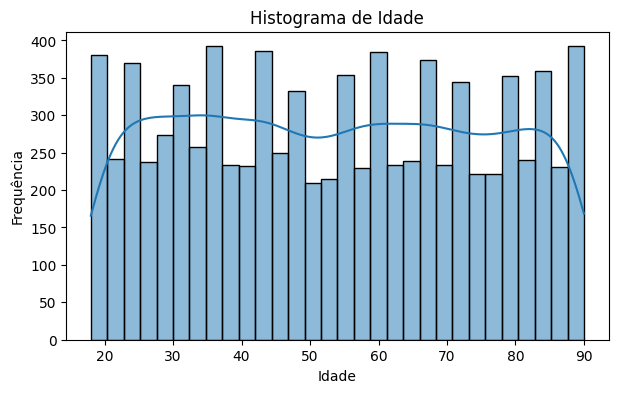

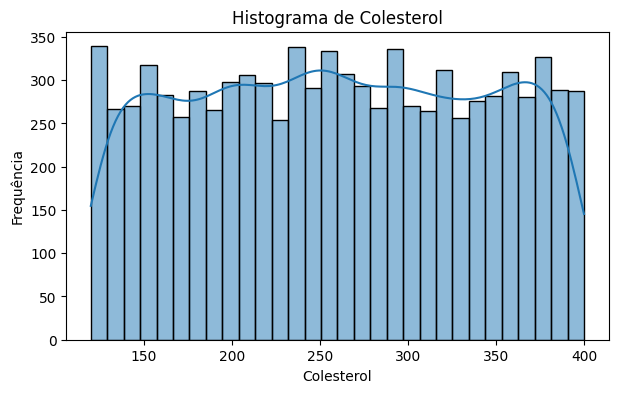

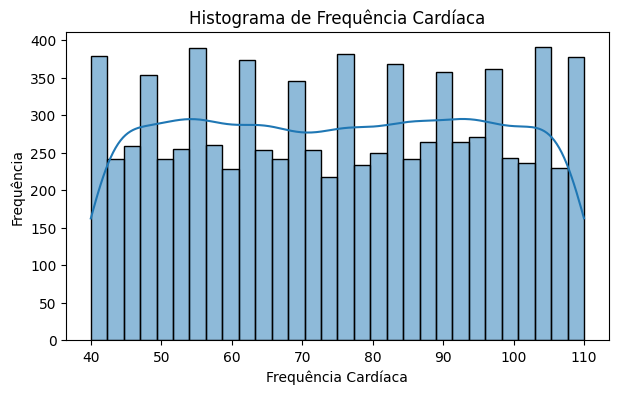

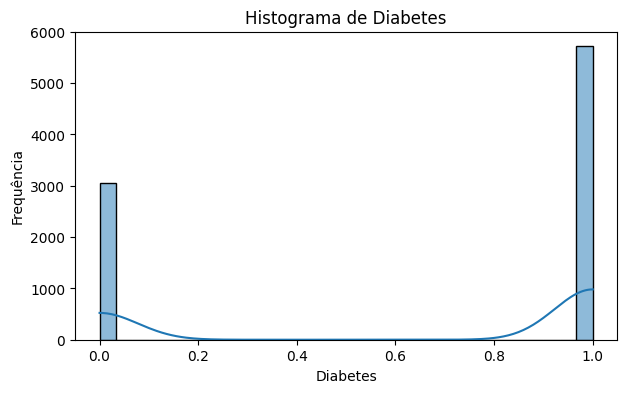

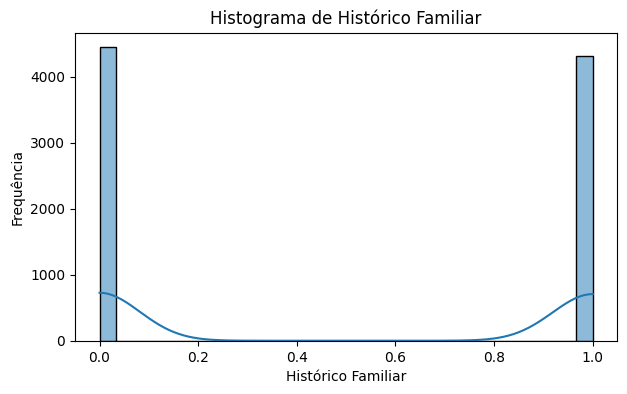

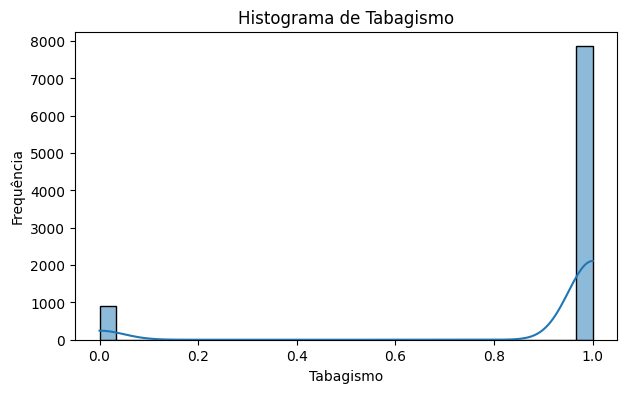

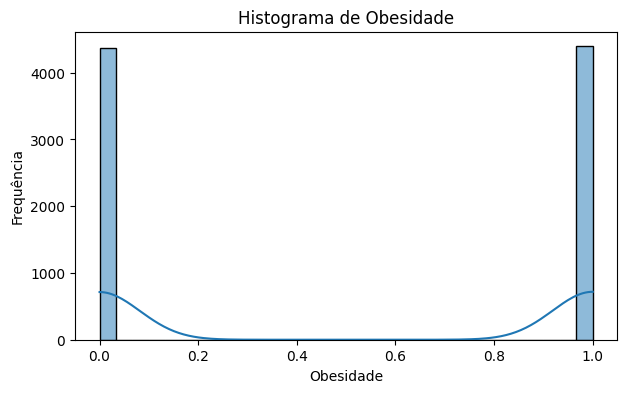

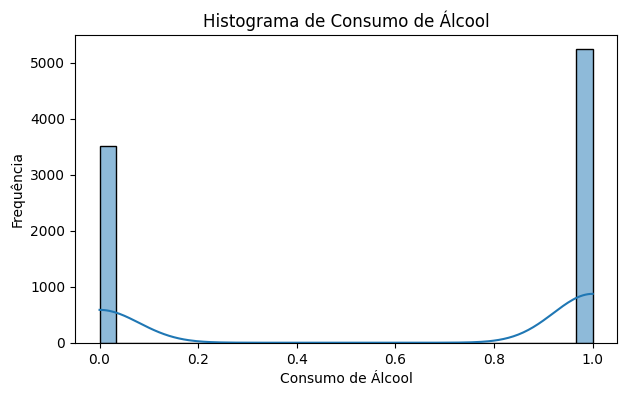

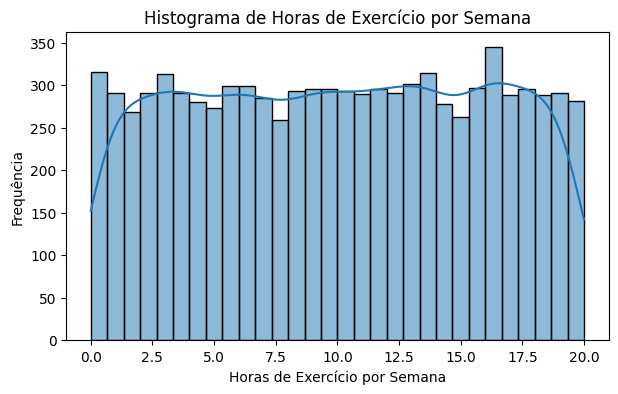

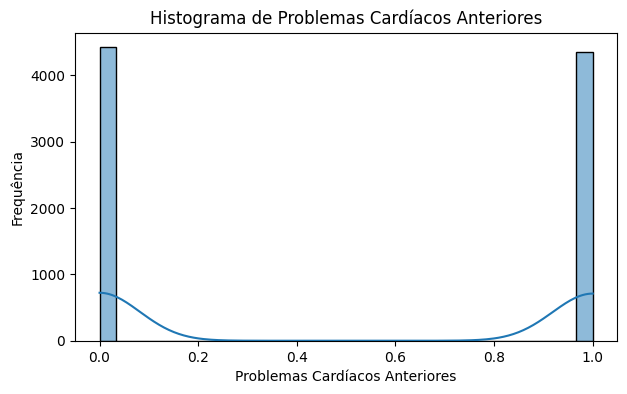

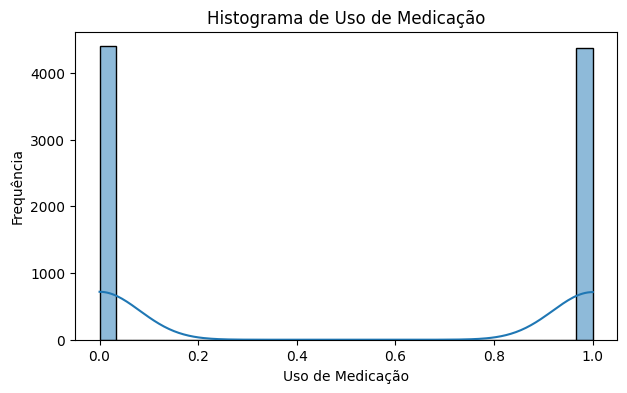

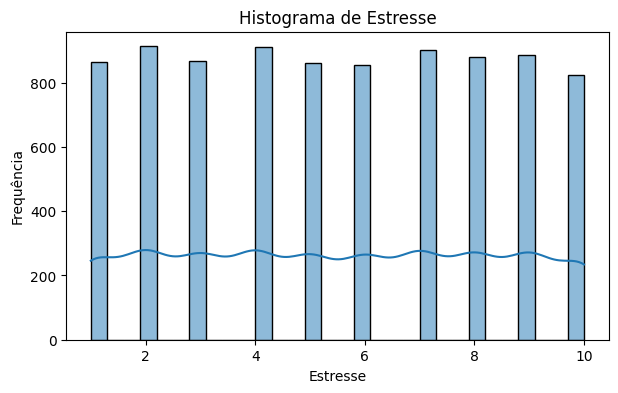

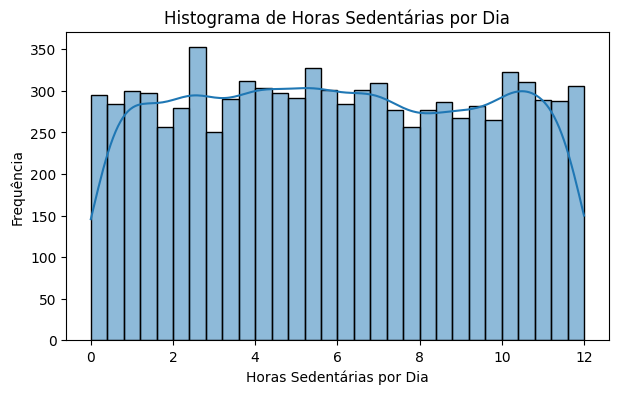

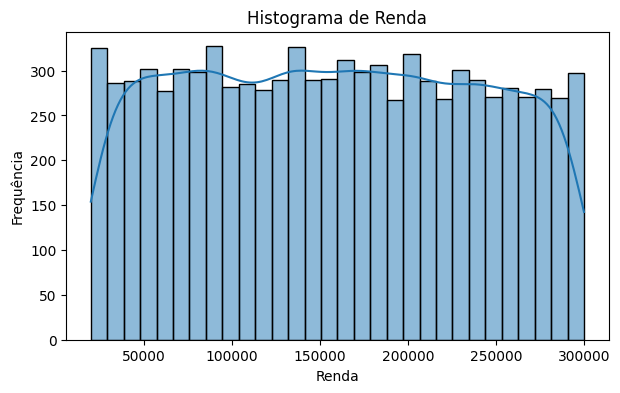

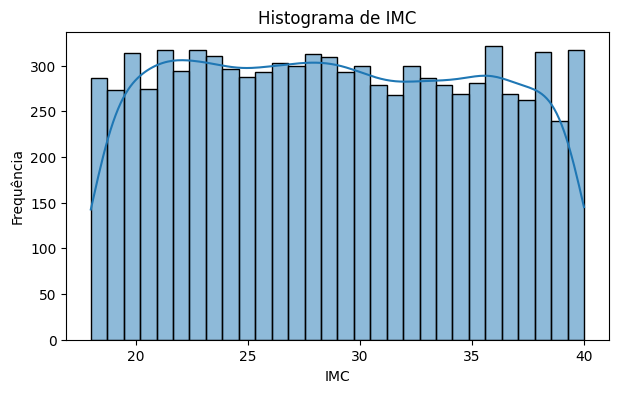

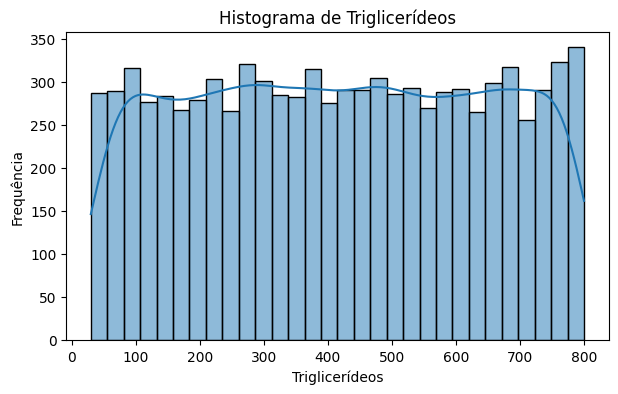

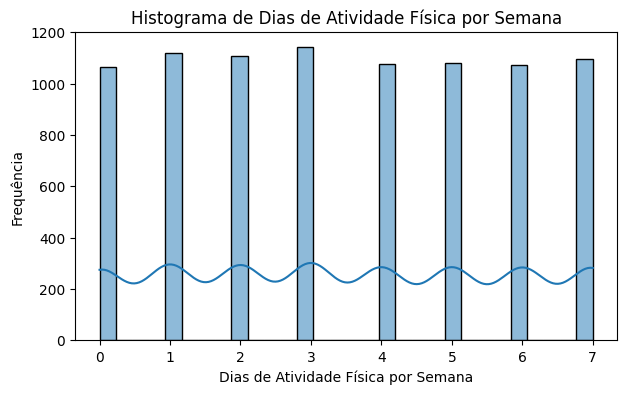

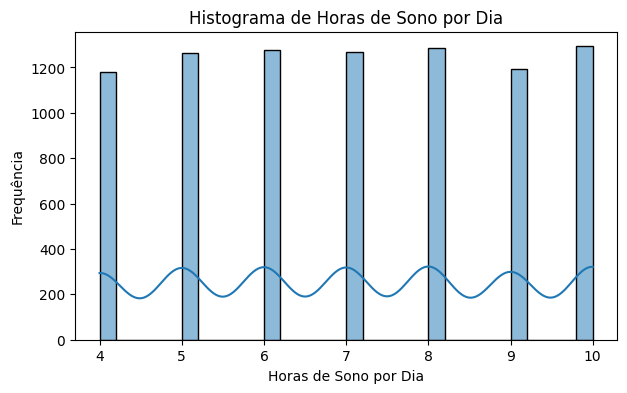

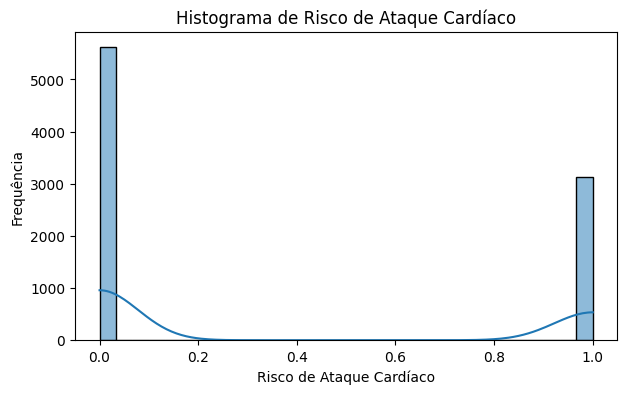

In [28]:
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns

for coluna in colunas_numericas:
    plt.figure(figsize=(7,4))
    sns.histplot(df[coluna], kde=True, bins=30)
    plt.title(f"Histograma de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.show()


In [41]:
#Idade
#O histograma de Idade apresenta distribuição relativamente uniforme entre 18 e 90 anos, sem concentração dominante em uma única faixa.
#Há alta dispersão, já que os valores variam por mais de 70 anos.
#A distribuição tende a ser quase uniforme, sem forma clara de cauda.
#Não há evidências visuais de outliers.

# Colesterol
#O colesterol apresenta concentração entre 180 e 330 mg/dL, indicando uma tendência central bem definida.
#A dispersão é moderada a alta, com valores entre 120 e 400.
#A distribuição é assimétrica à direita, mostrando alguns indivíduos com colesterol muito alto.
#Existem outliers leves acima de 360.

#Frequência Cardíaca

#O histograma mostra que a maior parte dos valores está entre 55 e 95 bpm.
#A dispersão é moderada, e os valores ficam entre 40 e 110 bpm.
#A distribuição é ligeiramente simétrica, com leve cauda à direita.
#Poucos valores próximos de 110 podem ser considerados extremos.

#Diabetes (0/1)

#A variável é binária, então o histograma mostra dois picos: 0 e 1.
#Não há dispersão numérica, apenas proporção entre classes.
#A distribuição é bimodal artificial, por ser uma variável categórica representada em números.

#Histórico Familiar (0/1)

#Também é variável binária.
#O histograma mostra a frequência de presença (1) e ausência (0).
#Sem dispersão contínua.
#Distribuição bimodal.

#Tabagismo (0/1)

#Mesma interpretação: variável binária.
#O gráfico mostra proporção entre fumantes e não fumantes.

#Obesidade (0/1)

#Binária.
#Distribuição bimodal.
#Sem dispersão contínua.

#Consumo de Álcool (0/1)

#Binária.
#Mostra apenas proporção entre consumidores e não consumidores.

#Horas de Exercício por Semana

#A concentração principal ocorre entre 5 e 15 horas/semana.
#A dispersão é alta, variando de 0 até quase 20 horas.
#Distribuição assimétrica à esquerda, indicando que poucas pessoas praticam exercício extremo.
#Poucos outliers em valores muito baixos ou muito altos.

#Problemas Cardíacos Anteriores (0/1)

#Binária.
#Distribuição com dois picos: 0 e 1.

#Uso de Medicação (0/1)

#Binária.
#Mesma interpretação das anteriores.

#Nível de Estresse

#O histograma mostra concentração entre 3 e 8 pontos.
#A dispersão é moderada.
#A forma tende a ser simétrica, com leve cauda à direita.
#Alguns valores extremos aparecem próximos a 10.

#Horas Sedentárias por Dia

#Variável com tendência central entre 3 e 9 horas.
#Alta dispersão (0 a 12 horas).
#A distribuição parece assimétrica à direita, com muitas pessoas passando longas horas sentadas.
#Possíveis outliers em valores extremos como 0 ou 12.

#Renda

#Renda apresenta altíssima dispersão, variando de ~20 mil até ~300 mil.
#A distribuição é fortemente assimétrica à direita, com muitos valores baixos e poucos extremamente altos.
#Existe presença clara de outliers (faixa muito alta).

#IMC

#Valores entre 18 e 40, com maior concentração entre 23 e 33.
#Dispersão moderada.
#Distribuição levemente assimétrica à direita.
#Alguns valores extremos próximos de 18 e 40.

#Triglicerídeos

#Variação de 30 a 800 mg/dL, indicando dispersão extremamente alta.
#A maioria dos valores está entre 150 e 500, mas com cauda longa para valores muito elevados.
#Distribuição fortemente assimétrica à direita.
#Muitos outliers acima de 600.

#Dias de Atividade Física por Semana

#Concentração entre 2 e 5 dias.
#Dispersão moderada.
#Distribuição relativamente simétrica, mas com leve cauda à esquerda (pessoas muito sedentárias).
#Poucos outliers em valores 0 e 7.

#Horas de Sono por Dia

#Valores entre 4 e 10 horas, com maior concentração entre 6 e 8 horas.
#Dispersão baixa a moderada.
#A distribuição é simétrica, parecida com uma curva normal.
#Sem outliers evidentes.

#Risco de Ataque Cardíaco (0/1)

#Variável binária.
#O histograma mostra proporções entre risco baixo e risco alto.
#Sem dispersão contínua.



###3.2 Visualizações

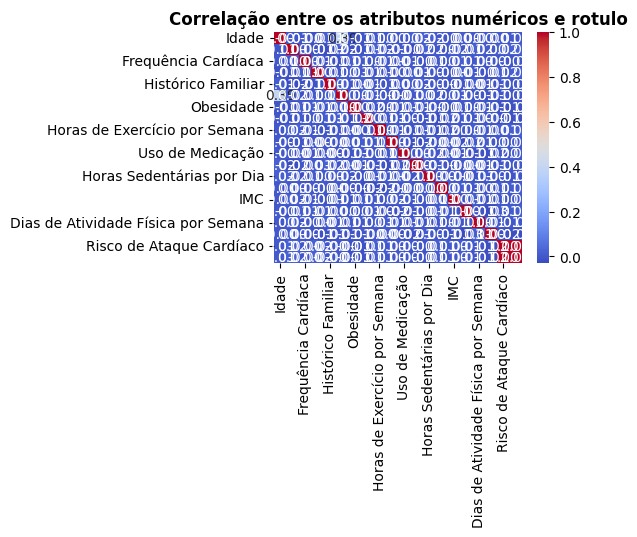

In [29]:
plt.figure(figsize=(4,3))
matriz_corr = df[atributos_numericos+[rotulo]].corr()
sns.heatmap(matriz_corr, annot=True,cmap='coolwarm', fmt='.2f')
plt.title('Correlação entre os atributos numéricos e rotulo', fontweight='bold')
plt.show()

<Figure size 1000x600 with 0 Axes>

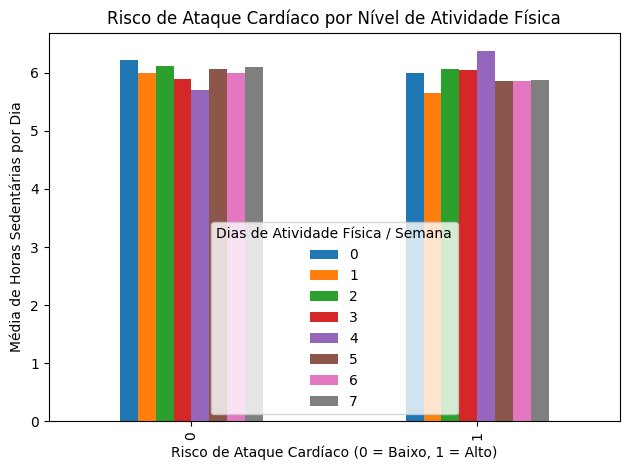

In [30]:
# Comparação entre estilo de vida e risco de ataque cardíaco
plt.figure(figsize=(10,6))

df.groupby(['Risco de Ataque Cardíaco', 'Dias de Atividade Física por Semana'])['Horas Sedentárias por Dia'].mean().unstack().plot(kind='bar')

plt.title("Risco de Ataque Cardíaco por Nível de Atividade Física")
plt.xlabel("Risco de Ataque Cardíaco (0 = Baixo, 1 = Alto)")
plt.ylabel("Média de Horas Sedentárias por Dia")
plt.legend(title="Dias de Atividade Física / Semana")
plt.tight_layout()
plt.show()


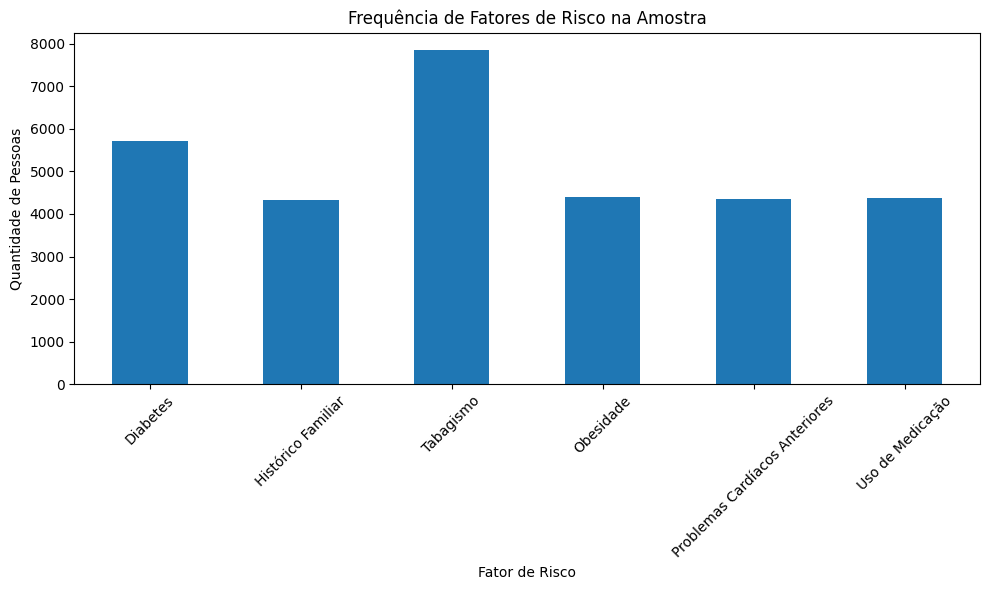

In [31]:
# Contagem de fatores de risco
fatores = ['Diabetes', 'Histórico Familiar', 'Tabagismo', 'Obesidade',
           'Problemas Cardíacos Anteriores', 'Uso de Medicação']

df[fatores].sum().plot(kind='bar', figsize=(10,6))

plt.title("Frequência de Fatores de Risco na Amostra")
plt.xlabel("Fator de Risco")
plt.ylabel("Quantidade de Pessoas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


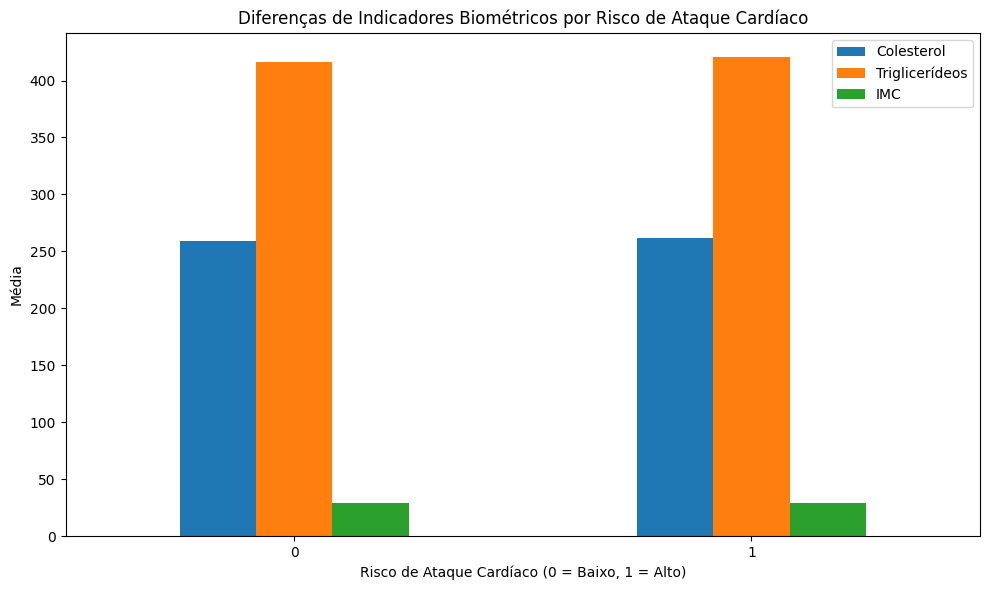

In [32]:
# Comparação de médias entre grupos com e sem risco
#o grupo de risco alto tem  triglicerídeos mais elevados, o próximo indicador relevante seria o Colesterol alto mas o IMC não demonstra relevância suficiente para o risco de ataque cardiáco
variaveis = ['Colesterol', 'Triglicerídeos', 'IMC']

df.groupby('Risco de Ataque Cardíaco')[variaveis].mean().plot(kind='bar', figsize=(10,6))

plt.title("Diferenças de Indicadores Biométricos por Risco de Ataque Cardíaco")
plt.xlabel("Risco de Ataque Cardíaco (0 = Baixo, 1 = Alto)")
plt.ylabel("Média")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#Sprint 2

##Etapa 1 - Identificação e discussão da forma da distribuição

In [32]:
#1. Idade

#A distribuição da idade é relativamente uniforme, sem concentração forte em um único intervalo.
#Não há caudas pronunciadas, indicando ausência de assimetria marcada.
#Trata-se de uma distribuição próxima ao uniforme.

#2. Colesterol

# A distribuição apresenta uma forma assimétrica à direita, com maior concentração entre 180 e 330 mg/dL.
#Há uma cauda longa em direção aos valores mais altos, indicando presença de indivíduos com colesterol elevado.
#Possíveis outliers aparecem acima de ~360 mg/dL.

#3. Frequência Cardíaca

#A distribuição é quase simétrica, com leve concentração em torno dos 70–90 bpm.
#Existe uma leve cauda à direita, mas nada extremo.
#A forma lembra uma curva aproximadamente normal.

#4. Diabetes (0/1)

#Distribuição bimodal, pois é uma variável binária.
#Não possui forma contínua; representa apenas proporções entre classes.

#Observação: o mesmo se aplica para Histórico Familiar, Tabagismo, Obesidade, Consumo de Álcool, Problemas Cardíacos Anteriores, Uso de Medicação e Risco de Ataque Cardíaco.

#5. Horas de Exercício por Semana

#A distribuição é assimétrica à esquerda, com muitos valores entre 5 e 15 horas.
#A cauda esquerda é maior, indicando presença de indivíduos com poucos exercícios semanais.
#Há poucos outliers tanto em valores baixos quanto muito altos.

#6. Nível de Estresse

#Forma moderadamente simétrica, mas com leve alongamento à direita.
#Concentração principal entre 3 e 8 pontos.
#Poucos extremos próximos a 10.

#7. Horas Sedentárias por Dia

#Distribuição assimétrica à direita: há maior frequência de pessoas com 6 a 10 horas sedentárias.
#Cauda da direita mais alongada.
#Valores extremos próximos de 12 horas sugerem sedentarismo extremo.

#8. Renda

#A renda possui distribuição fortemente assimétrica à direita, típica de dados socioeconômicos.
#Grande concentração nos valores baixos e média baixa, acompanhada de longa cauda direita e outliers em rendas muito altas.
#Distribuição altamente distorcida (skewed).

#9. IMC

#A forma da distribuição é moderadamente assimétrica à direita, com concentração em torno de IMC 24–32.
#Poucos valores extremos próximos de 18 e 40 indicam diversidade nos perfis corporais.

#10. Triglicerídeos

#Distribuição com assimetria acentuada à direita.
#Muito concentrada entre 150 e 500 mg/dL, mas com longa cauda e diversos valores extremos.
#É uma variável com significativa variabilidade intra-grupo.

#11. Dias de Atividade Física por Semana

#A distribuição é quase simétrica, concentrada entre 2 e 5 dias.
#Há cauda esquerda mais leve, associada aos indivíduos pouco ativos.
#Poucos valores extremos em 0 e 7.

#12. Horas de Sono por Dia

#A forma é simétrica, semelhante a uma distribuição normal, com pico entre 6 e 8 horas.
#A dispersão é baixa e não há valores fora do esperado biologicamente.
#É uma das distribuições mais “comportadas” do conjunto.

##Etapa 2 - Cálculo e interpretação de correlações entre variáveis: Pearson ou Spearman

In [33]:
#Correlação com risco cardíaco
df[["Colesterol", "Triglicerídeos", "IMC", "Idade", "Risco de Ataque Cardíaco"]].corr(method="pearson")



,Colesterol,Triglicerídeos,IMC,Idade,Risco de Ataque Cardíaco
Colesterol,1.000000,-0.005454,0.017292,-0.009107,0.019340
Triglicerídeos,-0.005454,1.000000,-0.005964,0.003415,0.010471
IMC,0.017292,-0.005964,1.000000,-0.002612,0.000020
Idade,-0.009107,0.003415,-0.002612,1.000000,0.006403
Risco de Ataque Cardíaco,0.019340,0.010471,0.000020,0.006403,1.000000


In [34]:
#Correlação entre estilo de vida
df[["Horas Sedentárias por Dia", "Dias de Atividade Física por Semana", "Estresse", "Tabagismo", "Consumo de Álcool","Risco de Ataque Cardíaco"]].corr(method="spearman")



,Horas Sedentárias por Dia,Dias de Atividade Física por Semana,Estresse,Tabagismo,Consumo de Álcool,Risco de Ataque Cardíaco
Horas Sedentárias por Dia,1.000000,-0.006116,-0.005385,0.015455,-0.012811,-0.005718
Dias de Atividade Física por Semana,-0.006116,1.000000,0.007488,-0.006342,0.001557,-0.005105
Estresse,-0.005385,0.007488,1.000000,-0.001797,-0.005026,-0.004115
Tabagismo,0.015455,-0.006342,-0.001797,1.000000,0.012754,-0.004051
Consumo de Álcool,-0.012811,0.001557,-0.005026,0.012754,1.000000,-0.013778
Risco de Ataque Cardíaco,-0.005718,-0.005105,-0.004115,-0.004051,-0.013778,1.000000


##Etapa 3 - Gráficos de dispersão

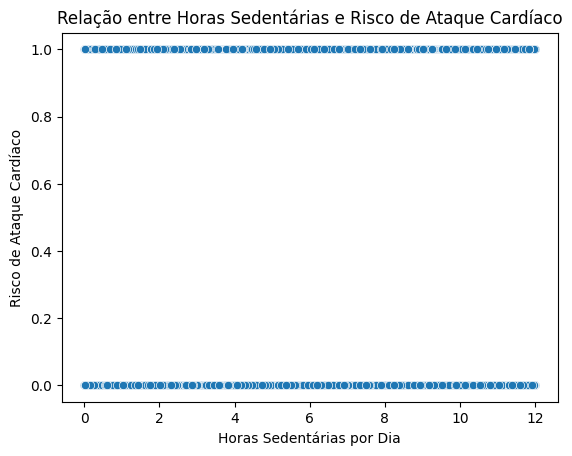

In [35]:
#Sedentarismo x Risco de Ataque Cardíaco
sns.scatterplot(data=df, x="Horas Sedentárias por Dia", y="Risco de Ataque Cardíaco")
plt.title("Relação entre Horas Sedentárias e Risco de Ataque Cardíaco")
plt.show()


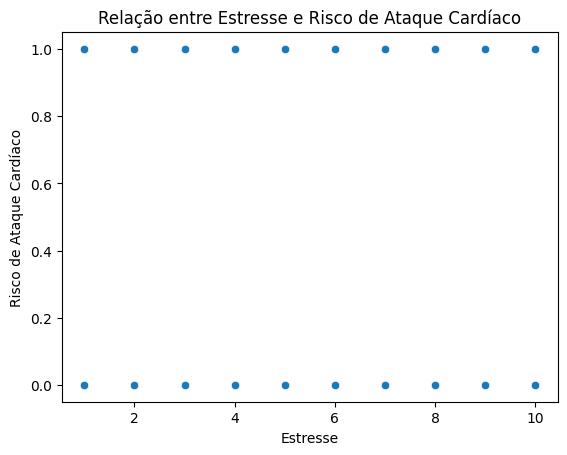

In [36]:
#Estresse x Risco de Ataque Cardíaco
sns.scatterplot(data=df, x="Estresse", y="Risco de Ataque Cardíaco")
plt.title("Relação entre Estresse e Risco de Ataque Cardíaco")
plt.show()


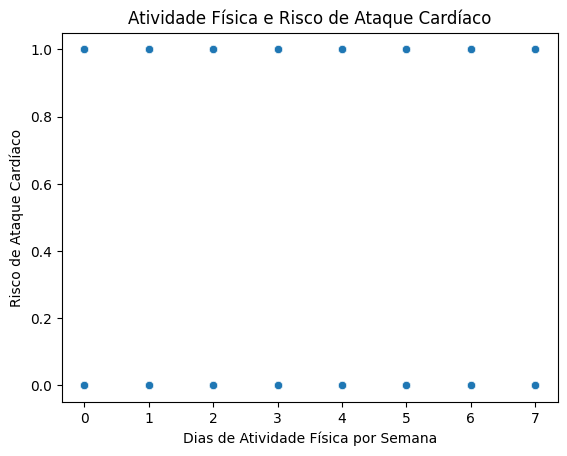

In [37]:
#Dias de Atividade Física x Risco de Ataque Cardíaco
sns.scatterplot(data=df, x="Dias de Atividade Física por Semana", y="Risco de Ataque Cardíaco")
plt.title("Atividade Física e Risco de Ataque Cardíaco")
plt.show()


##Etapa 4 - Conclusão


A análise exploratória das variáveis de saúde revelou um conjunto de padrões importantes para a compreensão do risco cardiovascular e da qualidade de vida dos indivíduos avaliados. Observou-se que diversos indicadores fisiológicos, como colesterol, triglicerídeos, horas sedentárias e IMC,apresentam alta variabilidade e forte assimetria à direita, indicando a presença de indivíduos com valores significativamente elevados que podem estar em condições de maior risco clínico. Variáveis comportamentais como tabagismo, consumo de álcool, histórico familiar e problemas cardíacos anteriores, embora binárias, mostraram prevalências consideráveis que reforçam a necessidade de monitoramento contínuo.

A relação entre hábitos de vida e saúde também ficou evidente. A presença de muitas horas sedentárias combinada a baixa frequência de atividade física sugere um padrão comportamental associado ao aumento do risco de ataque cardíaco,achado compatível com literatura médica. Além disso, a distribuição de estresse, sono e exercício indica que os indivíduos apresentam rotinas heterogêneas, o que impacta diretamente bem-estar físico e mental. A renda, por ser altamente desigual, pode refletir diferenças no acesso a cuidados médicos, nutrição adequada e estilo de vida mais saudável.

Esses resultados têm implicações práticas relevantes:

práticas preventivas devem ser priorizadas para grupos com valores extremos de colesterol, triglicerídeos e sedentarismo;

estratégias educativas voltadas ao aumento da atividade física podem reduzir riscos associados;

intervenções de saúde pública devem considerar fatores socioeconômicos para maior efetividade;

variáveis binárias associadas a comportamentos de risco podem ser usadas para segmentar campanhas ou triagens clínicas.

Em síntese, a análise demonstra que o comportamento, as condições socioeconômicas e fatores biométricos convergem para explicar o risco cardiovascular, reforçando a importância de monitoramento precoce e educação em saúde como ferramentas essenciais para promover bem-estar e prevenir doenças.
